# Exploration : prédire l'Elo à partir des coups (Blitz 3 min)

**Question** : peut-on deviner l'Elo d'un joueur uniquement à partir de *sa* partie (ses coups, sa gestion de la pendule) ?

Ce notebook ne construit **pas** de modèle. Il prépare des données propres et cohérentes, puis regarde quelles
informations contenues dans les coups semblent liées à l'Elo.

1. Chargement des parties Blitz 180+0 / 180+2
2. Qualité des données et nettoyage (niveau partie)
3. Passage à 1 ligne par joueur + filtre des Elo provisoires
4. La cible : distribution de l'Elo, joueurs répétés, baseline
5. Features candidates (partie, coups SAN, pendule, ouverture) vs Elo
6. Les parties avec évaluation (`%eval`)
7. Sauvegarde et bilan

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import plotly.express as px
import polars as pl

RAW_PATH = Path("../Data/blitz_180_raw.parquet")
OUT_PATH = Path("../Data/blitz_180_joueurs.parquet")

pl.Config.set_tbl_rows(20)
plt.rcParams["figure.dpi"] = 110

## 1. Chargement

`blitz_180_raw.parquet` (créé par le notebook 00) = les 2M premières parties du fichier de septembre
(~24 h du 1er sept.), filtrées sur les cadences **180+0** et **180+2** (cf. notebook 02). Pourquoi une seule famille de cadence :
- l'Elo Lichess est **propre à chaque cadence** (un 1800 en bullet n'est pas un 1800 en blitz) ;
- la pendule n'est comparable qu'entre parties jouées avec le même temps.

Les coups sont déjà découpés en une liste `moves` de `{san, clk, eval}`.

In [2]:
games = pl.read_parquet(RAW_PATH)
print(games.shape)
games.select("White", "WhiteElo", "Black", "BlackElo", "Result", "TimeControl", "Termination", "n_moves").head()

(557237, 21)


White,WhiteElo,Black,BlackElo,Result,TimeControl,Termination,n_moves
str,i32,str,i32,str,str,str,u32
"""DOMI60FR""",1735,"""Holizox""",1664,"""1/2-1/2""","""180+2""","""Normal""",99
"""Q8KSA""",1991,"""IRS007""",2045,"""1-0""","""180+0""","""Normal""",85
"""MiltonMorales""",2224,"""Glaidel""",2217,"""0-1""","""180+0""","""Normal""",28
"""nallek""",1744,"""Botonems""",1649,"""1-0""","""180+0""","""Time forfeit""",65
"""evgeniy_duk""",1557,"""Juanca_Master_Mind""",1611,"""0-1""","""180+2""","""Normal""",70


In [3]:
# Un coup = san (notation algébrique), clk (temps restant après le coup), eval (évaluation moteur, rare)
games["moves"][0][:6].to_list()

[{'san': 'd4', 'clk': '0:03:00', 'eval': None},
 {'san': 'd5', 'clk': '0:03:00', 'eval': None},
 {'san': 'c4', 'clk': '0:03:01', 'eval': None},
 {'san': 'e5', 'clk': '0:02:59', 'eval': None},
 {'san': 'cxd5', 'clk': '0:03:01', 'eval': None},
 {'san': 'exd4', 'clk': '0:02:59', 'eval': None}]

`n_moves` compte les **demi-coups** (un coup blanc *ou* un coup noir).

In [4]:
games["TimeControl"].value_counts(sort=True)

TimeControl,count
str,u32
"""180+0""",378584
"""180+2""",178653


## 2. Qualité des données (niveau partie)

### 2.1 Valeurs manquantes

In [5]:
games.null_count().transpose(include_header=True, column_names=["n_null"]).filter(pl.col("n_null") > 0)

column,n_null
str,u32
"""WhiteRatingDiff""",1514
"""BlackRatingDiff""",1514
"""WhiteTitle""",553017
"""BlackTitle""",552988


Seuls les titres et `RatingDiff` ont des trous :
- titre absent = joueur non titré, c'est normal ;
- `RatingDiff` manque pour 1 514 parties : très probablement les parties abandonnées (1 571), qui ne changent pas l'Elo.
  Ces lignes seront de toute façon retirées par les filtres plus bas.

### 2.2 Joueurs titrés et BOT

In [6]:
pl.concat([games["WhiteTitle"], games["BlackTitle"]]).drop_nulls().value_counts(sort=True)

WhiteTitle,count
str,u32
"""BOT""",3060
"""FM""",2032
"""CM""",1108
"""IM""",852
"""NM""",777
"""GM""",399
"""WFM""",103
"""WCM""",72
"""WIM""",27


`BOT` = programme d'ordinateur : ni son Elo ni ses coups ne décrivent un humain. On retire **toute la partie**
(jouer contre un bot n'est pas une partie « normale » pour l'humain non plus).
Les autres titres (CM, FM, IM, GM…) sont de vrais joueurs forts : on les garde.

### 2.3 Comment se terminent les parties ?

In [7]:
games.group_by("Termination").agg(n=pl.len(), pct=(pl.len() / games.height * 100).round(2)).sort("n", descending=True)

Termination,n,pct
str,u32,f64
"""Normal""",413316,74.17
"""Time forfeit""",142272,25.53
"""Abandoned""",1571,0.28
"""Insufficient material""",73,0.01
"""Rules infraction""",5,0.0


- `Abandoned` : partie quittée, souvent avant d'avoir vraiment joué ; `Rules infraction` : sanction (triche…).
  Les coups ne sont pas représentatifs → **retirées**.
- `Time forfeit` (perte au temps) et `Insufficient material` (temps écoulé mais l'adversaire ne peut plus mater → nulle)
  sont des fins normales en blitz → gardées.

### 2.4 Longueur des parties

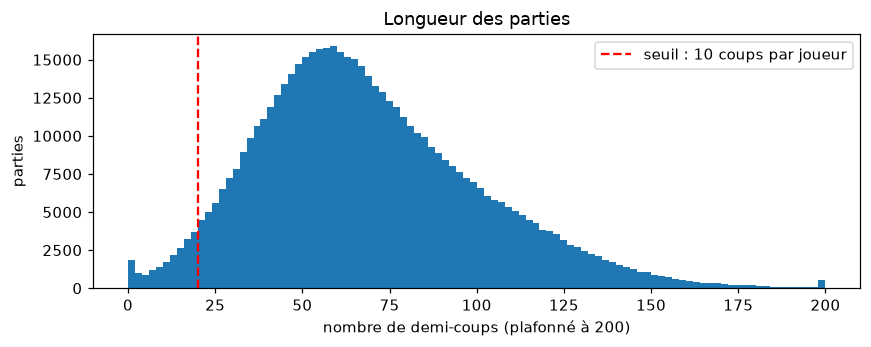

In [8]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(games["n_moves"].clip(upper_bound=200), bins=100)
ax.axvline(20, color="red", ls="--", label="seuil : 10 coups par joueur")
ax.set(xlabel="nombre de demi-coups (plafonné à 200)", ylabel="parties", title="Longueur des parties")
ax.legend()
plt.show()

Le notebook 02 a montré que les parties très courtes sont surtout des pertes au temps « immédiates » (joueur absent) ;
à partir de ~10 coups par joueur ce taux se stabilise. Seuil retenu : **≥ 20 demi-coups**. En dessous, il y a de
toute façon trop peu de coups pour juger un niveau.

### 2.5 Application des filtres

In [9]:
est_bot = (pl.col("WhiteTitle") == "BOT").fill_null(False) | (pl.col("BlackTitle") == "BOT").fill_null(False)
filtres = {
    "BOT": ~est_bot,
    "Abandoned / Rules infraction": ~pl.col("Termination").is_in(["Abandoned", "Rules infraction"]),
    "moins de 10 coups par joueur": pl.col("n_moves") >= 20,
}

clean, bilan = games, []
for nom, f in filtres.items():
    avant = clean.height
    clean = clean.filter(f)
    bilan.append({"filtre": nom, "parties retirées": avant - clean.height, "restantes": clean.height})
pl.DataFrame(bilan)

filtre,parties retirées,restantes
str,i64,i64
"""BOT""",1610,555627
"""Abandoned / Rules infraction""",1576,554051
"""moins de 10 coups par joueur""",18165,535886


### 2.6 Le joueur et son adversaire ont des Elo très proches

In [10]:
clean.select(
    corr_elo_blanc_noir=pl.corr("WhiteElo", "BlackElo"),
    ecart_median=(pl.col("WhiteElo") - pl.col("BlackElo")).abs().median(),
)

corr_elo_blanc_noir,ecart_median
f64,f64
0.95776,30.0


Corrélation de **0,96** entre l'Elo des Blancs et celui des Noirs, écart médian de 30 points : Lichess apparie des
joueurs de niveau très proche. Deux conséquences :
- l'Elo adverse prédirait presque parfaitement l'Elo du joueur → **fuite** : jamais en feature
  (ni `RatingDiff`, qui dépend des deux Elo) ;
- le **résultat** de la partie devrait dire peu de choses sur le niveau absolu, puisqu'on joue contre quelqu'un
  de son niveau (vérifié en section 5).

## 3. Une ligne par joueur

La cible est l'Elo d'**un** joueur, prédit à partir de **ses** coups. Chaque partie donne donc 2 lignes :
- Blancs : demi-coups 0, 2, 4… ;
- Noirs : demi-coups 1, 3, 5…

Pour chaque joueur on garde ses coups SAN et sa pendule convertie en secondes.

**Rappel Polars pour lire la cellule suivante.** Une expression Polars est une *recette* : elle ne calcule rien
tant qu'on ne l'utilise pas dans un `select` / `with_columns`, où elle est appliquée à chaque ligne.

| expression | ce qu'elle fait | exemple |
|---|---|---|
| `pl.col("White")` | prend **la colonne** `White` (valeur différente à chaque ligne) | `Alice`, `Chloé` |
| `pl.lit("White")` | écrit **la valeur fixe** `"White"` sur toutes les lignes | `White`, `White` |
| `.struct.field("clk")` | dans un objet `{san, clk, eval}`, prend le champ `clk` | `{san: "e4", clk: "0:02:59"}` → `"0:02:59"` |
| `.list.eval(expr)` | applique `expr` à **chaque élément** d'une liste ; `pl.element()` = l'élément en cours | `[{san: "e4", …}, {san: "Nf3", …}]` → `["e4", "Nf3"]` |
| `.list.gather_every(2, offset)` | prend 1 élément sur 2 à partir de la position `offset` | `[e4, c5, Nf3, d6]` → offset 0 : `[e4, Nf3]`, offset 1 : `[c5, d6]` |
| `.str.to_time("%H:%M:%S")` | transforme un texte en heure | `"0:02:59"` → `00:02:59` |
| `.dt.minute()`… | extrait les minutes d'une heure (`.cast(pl.Int32)` : sinon entier trop petit, max 127) | `00:02:59` → `2` |
| `.replace_strict({...})` | remplace selon un dictionnaire, **erreur** si une valeur n'y est pas | `"1-0"` → `1.0` |
| `pl.concat([a, b])` | empile deux tables qui ont les mêmes colonnes | |

**Ce que fait la cellule** : `un_cote(couleur, offset, score)` fabrique, à partir de `clean`, la table d'**une** couleur
(1 ligne par partie : nom, Elo, score et coups de ce joueur seulement). On l'appelle pour les Blancs (offset 0, demi-coups
0, 2, 4…) puis pour les Noirs (offset 1, demi-coups 1, 3, 5…), et on empile les deux tables : **2 lignes par partie**.

In [11]:
t = pl.element().struct.field("clk").str.to_time("%H:%M:%S")
en_secondes = t.dt.hour().cast(pl.Int32) * 3600 + t.dt.minute().cast(pl.Int32) * 60 + t.dt.second().cast(pl.Int32)
score_blanc = pl.col("Result").replace_strict({"1-0": 1.0, "0-1": 0.0, "1/2-1/2": 0.5})


def un_cote(couleur, offset, score):
    coups = pl.col("moves").list.gather_every(2, offset)  # 1 demi-coup sur 2 = les coups de ce joueur
    return clean.select(
        game_id=pl.col("Site").str.extract(r"lichess\.org/(\w+)"),
        joueur=pl.col(couleur),
        couleur=pl.lit(couleur),
        elo=pl.col(f"{couleur}Elo"),
        rating_diff=pl.col(f"{couleur}RatingDiff"),
        cadence=pl.col("TimeControl"),
        score=score,
        termination=pl.col("Termination"),
        eco=pl.col("ECO"),
        san=coups.list.eval(pl.element().struct.field("san")),
        clk=coups.list.eval(en_secondes),
        a_eval=pl.col("moves").list.eval(pl.element().struct.field("eval").is_not_null()).list.any(),
    )


joueurs = pl.concat([un_cote("White", 0, score_blanc), un_cote("Black", 1, 1 - score_blanc)])
del games, clean  # libère la mémoire
print(joueurs.shape)
joueurs.head(3)

(1071772, 12)


game_id,joueur,couleur,elo,rating_diff,cadence,score,termination,eco,san,clk,a_eval
str,str,str,i32,i32,str,f64,str,str,list[str],list[i32],bool
"""IMOSvErG""","""DOMI60FR""","""White""",1735,-2,"""180+2""",0.5,"""Normal""","""D08""","[""d4"", ""c4"", … ""Kc4""]","[180, 181, … 88]",false
"""bs18a5LO""","""Q8KSA""","""White""",1991,7,"""180+0""",1.0,"""Normal""","""C42""","[""e4"", ""Nf3"", … ""Qe6+""]","[180, 179, … 27]",false
"""YXYiz29z""","""MiltonMorales""","""White""",2224,-6,"""180+0""",0.0,"""Normal""","""B23""","[""e4"", ""Nc3"", … ""h5""]","[180, 179, … 169]",false


### 3.1 Les Elo provisoires

Un nouveau compte démarre à 1500 et son Elo est **provisoire** tant que Lichess n'est pas sûr de son niveau :
il bouge alors beaucoup à chaque partie. Ce n'est pas une bonne cible : il ne reflète pas encore le vrai niveau.

Le PGN ne donne pas l'incertitude de l'Elo, mais il donne `RatingDiff` (points gagnés/perdus sur la partie) :
une grosse variation = Elo encore incertain.

shape: (10, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1.069534e6 │
│ null_count ┆ 0.0        │
│ mean       ┆ 6.816035   │
│ std        ┆ 12.833451  │
│ min        ┆ 0.0        │
│ 50%        ┆ 6.0        │
│ 90%        ┆ 8.0        │
│ 95%        ┆ 10.0       │
│ 99%        ┆ 38.0       │
│ max        ┆ 700.0      │
└────────────┴────────────┘


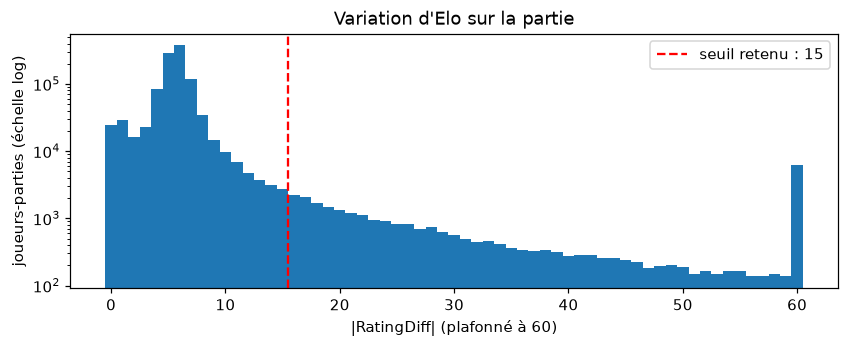

In [12]:
abs_diff = joueurs["rating_diff"].abs().drop_nulls()
print(abs_diff.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(abs_diff.clip(upper_bound=60), bins=61, range=(-0.5, 60.5), log=True)
ax.axvline(15.5, color="red", ls="--", label="seuil retenu : 15")
ax.set(xlabel="|RatingDiff| (plafonné à 60)", ylabel="joueurs-parties (échelle log)", title="Variation d'Elo sur la partie")
ax.legend()
plt.show()

In [13]:
# Les grosses variations sont-elles bien des comptes récents (Elo proche de 1500) ?
(
    joueurs.drop_nulls("rating_diff")
    .group_by(provisoire=pl.col("rating_diff").abs() > 15)
    .agg(
        n=pl.len(),
        elo_moyen=pl.col("elo").mean().round(),
        pct_elo_1400_1600=(((pl.col("elo") - 1500).abs() <= 100).mean() * 100).round(1),
    )
)

provisoire,n,elo_moyen,pct_elo_1400_1600
bool,u32,f64,f64
false,1038592,1692.0,17.3
true,30942,1477.0,21.0


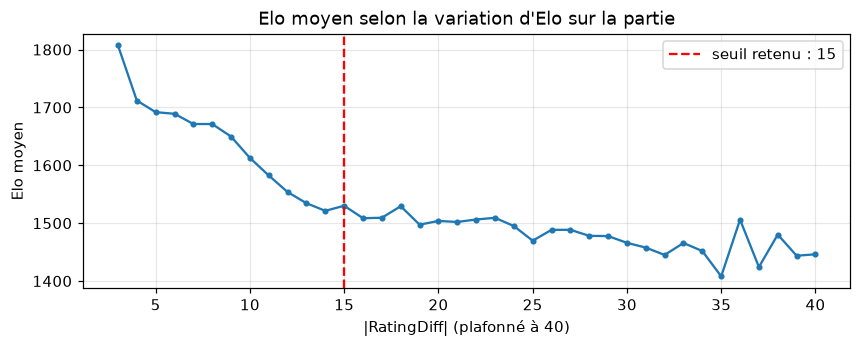

In [14]:
# Elo moyen selon |RatingDiff| : à partir d'où tombe-t-on sur une autre population ?
elo_par_diff = (
    joueurs.drop_nulls("rating_diff")
    .group_by(abs_diff=pl.col("rating_diff").abs().clip(upper_bound=40))  # 40 = "40 et plus"
    .agg(n=pl.len(), elo_moyen=pl.col("elo").mean())
    .filter(pl.col("abs_diff") >= 3)
    .sort("abs_diff")
)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(elo_par_diff["abs_diff"], elo_par_diff["elo_moyen"], marker=".")
ax.axvline(15, color="red", ls="--", label="seuil retenu : 15")
ax.set(xlabel="|RatingDiff| (plafonné à 40)", ylabel="Elo moyen", title="Elo moyen selon la variation d'Elo sur la partie")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

- La grande majorité des variations se situe entre 4 et 8 points (95 % ≤ 10), puis il y a une longue queue.
- **Comment choisir le seuil ?** Sur le graphe de l'Elo moyen selon |RatingDiff| :
  - jusqu'à ~10 points, l'Elo moyen reste proche de la moyenne générale (~1650-1690) : joueurs « normaux » ;
  - entre 10 et 13, il chute ;
  - à partir de ~13-15, il se stabilise vers 1450-1500 (**plateau**) : au-delà, c'est toujours la même population,
    des comptes récents partis de 1500 dont l'Elo n'est pas encore stable.

Seuil retenu : **|RatingDiff| ≤ 15**, le début du plateau (≈ 3 % des lignes retirées). Tout seuil entre 12 et 20 serait
défendable : 20 retirerait seulement 0,8 % de lignes en moins, ce qui ne change pas les conclusions.
À vérifier dans le notebook modèle : l'erreur est-elle plus grande sur les joueurs entre 15 et 20 ?

In [15]:
avant = joueurs.height
joueurs = joueurs.filter(pl.col("rating_diff").abs() <= 15)  # retire aussi les RatingDiff manquants
print(f"retirés : {avant - joueurs.height} ({(avant - joueurs.height) / avant:.1%}) -> restants : {joueurs.height}")

retirés : 33180 (3.1%) -> restants : 1038592


### 3.2 Les pendules « anormales »

On veut comparer la gestion du temps entre joueurs : il faut que tous partent des mêmes règles. Deux cas cassent ça :
- **berserk** : en tournoi Arena, un joueur peut diviser son temps par deux → sa pendule démarre à 90 s au lieu de 180 s ;
- **temps ajouté** : l'adversaire peut offrir +15 s → la pendule remonte de plus que l'incrément entre deux coups.

In [16]:
inc = pl.col("cadence").str.extract(r"\+(\d+)").cast(pl.Int32)  # incrément : 0 ou 2 s
debut = pl.col("clk").list.first()
remontee = pl.col("clk").list.diff().list.max()  # plus forte remontée de la pendule entre deux coups

joueurs.select(
    berserk=(debut <= 150).sum(),
    autre_depart=((debut > 150) & ~debut.is_between(170, 182)).sum(),
    temps_ajoute=(remontee > inc).sum(),
)

berserk,autre_depart,temps_ajoute
u32,u32,u32
13110,62,1452


In [17]:
avant = joueurs.height
joueurs = joueurs.filter(debut.is_between(170, 182), remontee <= inc)
print(f"retirés : {avant - joueurs.height} ({(avant - joueurs.height) / avant:.1%}) -> restants : {joueurs.height}")

retirés : 14607 (1.4%) -> restants : 1023985


## 4. La cible : l'Elo

### 4.1 Distribution

In [18]:
joueurs["elo"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

statistic,value
str,f64
"""count""",1.023985e6
"""null_count""",0.0
"""mean""",1689.223397
"""std""",350.432521
"""min""",400.0
"""1%""",871.0
"""25%""",1454.0
"""50%""",1708.0
"""75%""",1931.0


In [19]:
# Histogramme calculé avec Polars (barres de 25 points) : plotly ne reçoit que ~200 points au lieu d'1M
histo = (
    joueurs.group_by("cadence", elo=pl.col("elo") // 25 * 25)
    .agg(n=pl.len())
    .with_columns(pct=pl.col("n") / pl.col("n").sum().over("cadence") * 100)
    .sort("elo")
)
fig = px.line(histo, x="elo", y="pct", color="cadence", title="Distribution de l'Elo selon la cadence (% par tranche de 25)")
fig.show()

In [20]:
(
    joueurs.group_by("cadence", "couleur")
    .agg(n=pl.len(), moyenne=pl.col("elo").mean().round(), ecart_type=pl.col("elo").std().round(), mediane=pl.col("elo").median())
    .sort("cadence", "couleur")
)

cadence,couleur,n,moyenne,ecart_type,mediane
str,str,u32,f64,f64,f64
"""180+0""","""Black""",348484,1714.0,345.0,1735.0
"""180+0""","""White""",348322,1714.0,345.0,1735.0
"""180+2""","""Black""",163574,1637.0,356.0,1648.0
"""180+2""","""White""",163605,1637.0,357.0,1647.0


- L'Elo a une forme de cloche : médiane ≈ 1710, écart-type ≈ 350, 98 % des lignes entre ~870 et ~2460.
  Les extrêmes sont rares : un modèle aura tendance à les ramener vers le centre.
- Blancs et Noirs ont la même distribution (normal : chaque partie fournit un joueur de chaque couleur, de niveaux proches).
- Les joueurs en **180+2** sont en moyenne ~80 points plus bas qu'en 180+0 : ce n'est pas exactement la même
  population. La cadence est à garder comme variable (ou à tester séparément).

### 4.2 Baseline : prédire toujours la même valeur

Le point de référence de tout futur modèle : prédire la médiane pour tout le monde.

In [21]:
mediane = joueurs["elo"].median()
mae = (joueurs["elo"] - mediane).abs().mean()
print(f"Prédire toujours {mediane:.0f} -> MAE = {mae:.0f} points d'Elo")

Prédire toujours 1708 -> MAE = 281 points d'Elo


### 4.3 Un même joueur apparaît plusieurs fois

In [22]:
par_joueur = joueurs.group_by("joueur").agg(n_parties=pl.len(), elo_std=pl.col("elo").std())
print(par_joueur["n_parties"].describe(percentiles=[0.5, 0.9, 0.99]))
par_joueur.select(
    n_joueurs=pl.len(),
    pct_joueurs_1_partie=((pl.col("n_parties") == 1).mean() * 100).round(1),
    pct_lignes_joueurs_10_parties_plus=(
        pl.col("n_parties").filter(pl.col("n_parties") >= 10).sum() / pl.col("n_parties").sum() * 100
    ).round(1),
    elo_std_median_meme_joueur=pl.col("elo_std").median(),
)

shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 149364.0 │
│ null_count ┆ 0.0      │
│ mean       ┆ 6.855635 │
│ std        ┆ 8.788346 │
│ min        ┆ 1.0      │
│ 50%        ┆ 4.0      │
│ 90%        ┆ 16.0     │
│ 99%        ┆ 43.0     │
│ max        ┆ 217.0    │
└────────────┴──────────┘


n_joueurs,pct_joueurs_1_partie,pct_lignes_joueurs_10_parties_plus,elo_std_median_meme_joueur
u32,f64,f64,f64
149364,21.7,60.7,5.656854


- ~149k joueurs distincts pour ~1M lignes ; médiane de 4 parties par joueur, jusqu'à 217 parties dans la journée.
- 61 % des lignes viennent de joueurs ayant joué au moins 10 parties.
- L'Elo d'un même joueur ne bouge presque pas sur la journée (écart-type médian ≈ 6 points).

→ Si un même joueur est à la fois dans le train et dans le test, le modèle peut « reconnaître » son style et
retrouver son Elo : le score serait trop optimiste. **Le split train/test doit se faire par joueur**
(ex. `GroupKFold` sur `joueur`).

## 5. Quelles informations des coups sont liées à l'Elo ?

On calcule des features simples par joueur-partie, uniquement avec Polars (pas d'échiquier) :
- **partie** : score, nombre de coups, perte au temps ;
- **coups SAN** : % de captures (`x`), d'échecs (`+`), de coups de pion, de dame, de roi ; roque et à quel coup ;
- **pendule** : temps moyen par coup et sa variabilité, temps passé sur les 10 premiers coups, % de coups joués
  en ≤ 1 s, % de coups joués avec moins de 20 s restantes, temps restant à la fin.

Temps passé sur un coup = temps restant au coup précédent − temps restant après ce coup + incrément (0 ou 2 s).

In [23]:
san = pl.col("san")
roque = san.list.eval(pl.element().str.starts_with("O-O"))

feats = joueurs.with_columns(
    temps=pl.col("clk").list.diff().list.drop_nulls() * -1 + inc,  # secondes passées par coup (sans le 1er)
).select(
    "elo", "cadence", "couleur",
    # partie
    "score",
    n_coups=san.list.len(),
    perd_au_temps=(pl.col("termination") == "Time forfeit") & (pl.col("score") == 0),
    # coups SAN
    pct_captures=san.list.eval(pl.element().str.contains("x")).list.mean(),
    pct_echecs=san.list.eval(pl.element().str.contains(r"\+")).list.mean(),
    pct_pions=san.list.eval(pl.element().str.contains(r"^[a-h]")).list.mean(),
    pct_dame=san.list.eval(pl.element().str.starts_with("Q")).list.mean(),
    pct_roi=san.list.eval(pl.element().str.starts_with("K")).list.mean(),
    a_roque=roque.list.any(),
    coup_du_roque=pl.when(roque.list.any()).then(roque.list.arg_max() + 1),
    # pendule
    temps_moyen=pl.col("temps").list.mean(),
    temps_std=pl.col("temps").list.std(),
    temps_10_premiers=pl.col("temps").list.head(10).list.sum(),
    pct_coups_rapides=pl.col("temps").list.eval(pl.element() <= 1).list.mean(),
    pct_zeitnot=pl.col("clk").list.eval(pl.element() < 20).list.mean(),
    temps_restant_fin=pl.col("clk").list.last(),
)
FEATURES = [c for c in feats.columns if c not in ("elo", "cadence", "couleur")]
feats.describe()

statistic,elo,cadence,couleur,score,n_coups,perd_au_temps,pct_captures,pct_echecs,pct_pions,pct_dame,pct_roi,a_roque,coup_du_roque,temps_moyen,temps_std,temps_10_premiers,pct_coups_rapides,pct_zeitnot,temps_restant_fin
str,f64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1.023985e6,"""1023985""","""1023985""",1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,846488.0,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6,1.023985e6
"""null_count""",0.0,"""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,177497.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1689.223397,null,null,0.499805,35.330241,0.124611,0.238231,0.063114,0.291367,0.126856,0.081662,0.826661,10.218166,4.073827,4.492321,26.591753,0.330443,0.055022,66.825873
"""std""",350.432521,null,null,0.488961,15.171346,null,0.063353,0.068897,0.087512,0.090854,0.095283,null,4.133861,1.706636,2.638683,18.417762,0.150627,0.115235,50.381949
"""min""",400.0,"""180+0""","""Black""",0.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",1454.0,null,null,0.0,24.0,null,0.2,0.0,0.230769,0.057971,0.0,null,7.0,2.852941,2.740415,14.0,0.222222,0.0,19.0
"""50%""",1708.0,null,null,0.5,33.0,null,0.235294,0.045455,0.285714,0.111111,0.04878,null,9.0,3.742857,3.886412,22.0,0.321429,0.0,62.0
"""75%""",1931.0,null,null,1.0,44.0,null,0.275862,0.095238,0.34375,0.179487,0.12766,null,12.0,4.967742,5.562512,33.0,0.428571,0.030303,107.0
"""max""",2985.0,"""180+2""","""White""",1.0,228.0,1.0,0.769231,0.722222,1.0,0.8,0.812081,1.0,48.0,21.333333,57.773889,198.0,1.0,0.979167,320.0


### 5.1 Moyenne de chaque feature par tranche d'Elo

On découpe l'Elo en tranches de 100 points et on trace la moyenne de chaque feature. Une courbe qui monte
ou descend nettement = feature potentiellement utile. Les tranches de moins de 1000 lignes sont retirées (trop bruitées).

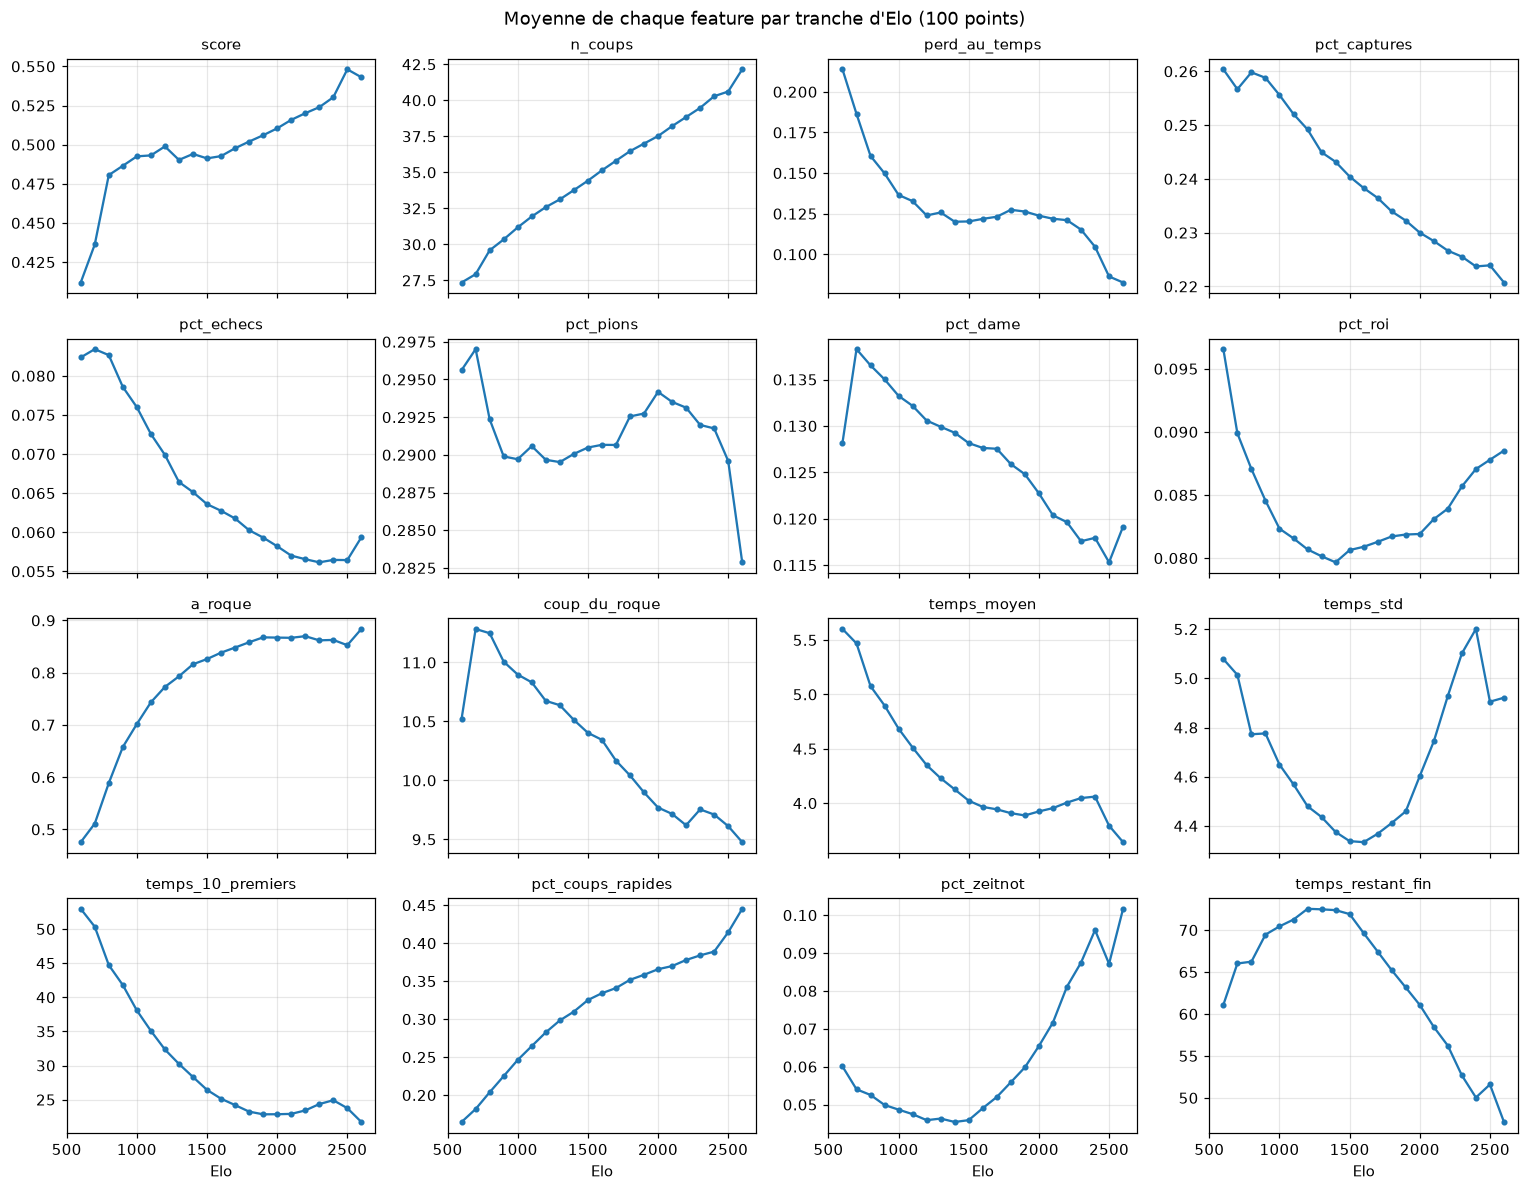

In [24]:
tranches = (
    feats.with_columns(tranche=pl.col("elo") // 100 * 100)
    .group_by("tranche")
    .agg(n=pl.len(), *[pl.col(c).cast(pl.Float64).mean() for c in FEATURES])
    .filter(pl.col("n") >= 1000)
    .sort("tranche")
)

fig, axes = plt.subplots(4, 4, figsize=(14, 11), sharex=True)
for ax, c in zip(axes.flat, FEATURES):
    ax.plot(tranches["tranche"], tranches[c], marker=".")
    ax.set_title(c, fontsize=10)
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("Elo")
fig.suptitle("Moyenne de chaque feature par tranche d'Elo (100 points)")
fig.tight_layout()
plt.show()

**Relations nettes et monotones** :
- `n_coups` : 27 → 42 coups : les joueurs forts jouent des parties plus longues (moins de gaffes qui terminent vite) ;
- `pct_captures` (26 % → 22 %) et `pct_echecs` (8 % → 6 %) : les joueurs faibles prennent et font échec plus souvent ;
- `a_roque` : 48 % → 87 %, et le roque arrive plus tôt chez les forts (`coup_du_roque`) ;
- `temps_10_premiers` : 53 s → 23 s : les forts connaissent leurs ouvertures et les jouent vite ;
- `pct_coups_rapides` : 17 % → 45 % de coups joués en ≤ 1 s.

**Relations en U (non monotones)** : `temps_std`, `pct_zeitnot`, `temps_restant_fin`, `pct_roi`.
Les forts jouent vite puis passent plus de temps en zeitnot (ils jouent jusqu'au bout au lieu d'abandonner).
Une corrélation (même de Spearman) sous-estime ces features ; un modèle non linéaire (arbres) pourra mieux les exploiter.

**Résultat de la partie** : `score` reste vers 0,5 au centre ; il ne s'écarte qu'aux extrémités (aux deux bouts,
on joue forcément contre plus fort ou plus faible que soi). Comme prévu en 2.6, il est peu informatif.

⚠️ Ce sont des **moyennes** : à l'intérieur de chaque tranche la dispersion est grande. Une seule partie reste bruitée.

### 5.2 Corrélations avec l'Elo

Corrélation de **Spearman** : calculée sur les rangs, elle capte les relations monotones même non linéaires
(-1 / +1 = relation parfaite, 0 = aucune relation monotone).

In [25]:
correlations = pl.DataFrame({
    "feature": FEATURES,
    "spearman": [
        feats.select(c, "elo").drop_nulls().select(pl.corr(pl.col(c).cast(pl.Float64), "elo", method="spearman")).item()
        for c in FEATURES
    ],
}).sort(pl.col("spearman").abs(), descending=True)

fig = px.bar(
    correlations.sort(pl.col("spearman").abs()), x="spearman", y="feature", orientation="h",
    title="Corrélation de Spearman avec l'Elo", height=500,
)
fig.show()
correlations

feature,spearman
str,f64
"""temps_10_premiers""",-0.263034
"""pct_coups_rapides""",0.248073
"""n_coups""",0.151797
"""pct_captures""",-0.119861
"""a_roque""",0.115499
"""temps_moyen""",-0.106025
"""temps_restant_fin""",-0.095782
"""coup_du_roque""",-0.08695
"""pct_zeitnot""",0.073568


- Aucune feature seule n'est fortement liée à l'Elo (|ρ| ≤ 0,26) : sur une seule partie, chaque indicateur est bruité.
- En tête : la **pendule** (temps sur les 10 premiers coups, % de coups rapides), puis la longueur de la partie,
  et le style (captures, roque).
- Le résultat (`score`, `perd_au_temps`) ne sert quasiment à rien, comme prévu.
- Plusieurs features mesurent la même chose (ex. `temps_10_premiers` et `pct_coups_rapides` = vitesse) :
  leur apport **combiné** devra être mesuré avec un modèle.

### 5.3 Les ouvertures : le premier coup des Blancs

In [26]:
premier = joueurs.filter(pl.col("couleur") == "White").select("elo", premier_coup=pl.col("san").list.first())
top5 = premier["premier_coup"].value_counts(sort=True).head(5)["premier_coup"].to_list()

ouvertures = (
    premier.with_columns(
        premier_coup=pl.when(pl.col("premier_coup").is_in(top5)).then("premier_coup").otherwise(pl.lit("autre")),
        tranche=pl.col("elo") // 200 * 200,
    )
    .group_by("tranche", "premier_coup")
    .agg(n=pl.len())
    .with_columns(total=pl.col("n").sum().over("tranche"))
    .filter(pl.col("total") >= 1000)
    .with_columns(pct=(pl.col("n") / pl.col("total") * 100).round(1))
    .sort("tranche", "premier_coup")
)
fig = px.bar(
    ouvertures, x="tranche", y="pct", color="premier_coup",
    title="Premier coup des Blancs selon l'Elo (% par tranche de 200)",
    category_orders={"premier_coup": top5 + ["autre"]},
)
fig.show()

`e4` domine chez les joueurs faibles (~62 % jusqu'à 1400) puis recule (~38 % vers 2600) au profit de `d4`, `Nf3`
et `c4`, des ouvertures plus « positionnelles ». Le répertoire d'ouverture porte donc de l'information sur le niveau
→ pistes : les premiers coups ou le code `ECO` en variables catégorielles, puis des n-grammes de coups.

## 6. Les parties avec évaluation (`%eval`)

Une partie contient des `%eval` quand quelqu'un a demandé l'analyse ordinateur de la partie sur Lichess : les deux
joueurs ont alors une évaluation à chaque coup. C'est très informatif (on pourrait mesurer la qualité de chaque coup)
mais disponible seulement pour une partie des données. Avant de décider quoi en faire, on regarde si ces parties
sont **représentatives**.

In [27]:
joueurs.group_by("a_eval").agg(
    n=pl.len(),
    pct=(pl.len() / joueurs.height * 100).round(1),
    elo_moyen=pl.col("elo").mean().round(),
    elo_std=pl.col("elo").std().round(),
)

a_eval,n,pct,elo_moyen,elo_std
bool,u32,f64,f64,f64
false,929671,90.8,1680.0,341.0
true,94314,9.2,1776.0,424.0


In [28]:
pct_eval = (
    joueurs.group_by(tranche=pl.col("elo") // 100 * 100)
    .agg(n=pl.len(), pct_eval=(pl.col("a_eval").mean() * 100).round(1))
    .filter(pl.col("n") >= 1000)
    .sort("tranche")
)
fig = px.line(pct_eval, x="tranche", y="pct_eval", markers=True, title="% de joueurs-parties avec %eval selon l'Elo")
fig.show()

9 % des lignes ont des évaluations, mais **pas au hasard** :
- Elo moyen plus haut (1776 contre 1680) et plus dispersé (écart-type 424 contre 341) ;
- la proportion varie énormément avec l'Elo : ~7 % vers 1600, ~19 % vers 2200, ~38 % vers 2400, plus de 60 % au-delà
  de 2600 (les parties des joueurs forts sont beaucoup plus souvent analysées), et un peu plus chez les très faibles.

Conséquences :
- la simple **présence** de `%eval` est liée à l'Elo : c'est un artefact, pas une information sur le jeu → à ne pas
  utiliser comme feature ;
- un modèle entraîné seulement sur les parties évaluées verrait une population d'Elo différente.

Décision reportée : (a) ignorer les évaluations, (b) modèle à part sur ce sous-ensemble, ou (c) feature
« qualité des coups » manquante pour ~91 % des lignes.

## 7. Sauvegarde

Table propre, 1 ligne par joueur et par partie, pour les étapes suivantes (features, modèles).

In [29]:
joueurs.write_parquet(OUT_PATH)
print(joueurs.shape, joueurs.columns)

(1023985, 12) ['game_id', 'joueur', 'couleur', 'elo', 'rating_diff', 'cadence', 'score', 'termination', 'eco', 'san', 'clk', 'a_eval']


## Bilan

**Préprocessing retenu** : 557 237 parties → **1 023 985 lignes joueur-partie**

| niveau | règle | retiré |
|---|---|---|
| partie | un joueur est un BOT | 1 610 parties |
| partie | Abandoned / Rules infraction | 1 576 parties |
| partie | moins de 10 coups par joueur | 18 165 parties |
| joueur | Elo provisoire (\|RatingDiff\| > 15 ou manquant) | 33 180 lignes (3,1 %) |
| joueur | pendule anormale (berserk, temps ajouté) | 14 607 lignes (1,4 %) |

**Ce qu'on a appris**
- Cible : Elo ≈ 1700 ± 350. Baseline « toujours la médiane » : **MAE = 281**.
- À ne jamais utiliser (fuites) : Elo adverse (corr. 0,96), `RatingDiff`, présence de `%eval`.
  Split train/test **par joueur**.
- Le signal le plus fort vient de la **pendule** (vitesse dans l'ouverture, coups rapides), puis de la longueur de
  partie, du style (captures, échecs, roque) et de l'ouverture. Aucune feature seule ne suffit (|ρ| ≤ 0,26) :
  il faudra les combiner.
- Plusieurs relations sont en U → comparer une régression linéaire et un modèle à arbres.

**Prochaines étapes** : régression linéaire sur ces features (split par joueur), à comparer à 281 ;
décider du traitement des évaluations ; features d'échiquier (python-chess).